<a href="https://colab.research.google.com/github/VictorTrasancos/Telco-Customer-Churn/blob/main/telco_customer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parte 0 - Bibliotecas

In [20]:
# Compilei aqui todas as bibliotecas utilizadas
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_curve, roc_curve, roc_auc_score, average_precision_score
from sklearn.model_selection import cross_val_predict
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.inspection import permutation_importance


# Parte 1 - Preparação dos Dados

In [22]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print('Dimensões', df.shape)
display(df.head())

df.dtypes

# Clientes com tenure = 0 ainda não possuem valores a ser cobrado
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.loc[df["TotalCharges"].isna() & (df["tenure"] == 0), "TotalCharges"] = 0.0

# Binarização de Churn e SeniorCitizen
df['y'] = df['Churn'].map({'Yes': 1, 'No': 0})
df['SeniorCitizen'] = df['SeniorCitizen'].replace({0: 'No', 1: 'Yes'})

# CustomerID não tem valor preditivo, apenas confundiria o modelo
X = df.drop(columns=['customerID', 'Churn', 'y'])
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Dimensões do conjunto de Treino: {X_train.shape}")
print(f"Dimensões do conjunto de Teste: {X_test.shape}")

print(X_train.info())

Dimensões (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dimensões do conjunto de Treino: (5634, 19)
Dimensões do conjunto de Teste: (1409, 19)
<class 'pandas.core.frame.DataFrame'>
Index: 5634 entries, 2142 to 860
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            5634 non-null   object 
 1   SeniorCitizen     5634 non-null   object 
 2   Partner           5634 non-null   object 
 3   Dependents        5634 non-null   object 
 4   tenure            5634 non-null   int64  
 5   PhoneService      5634 non-null   object 
 6   MultipleLines     5634 non-null   object 
 7   InternetService   5634 non-null   object 
 8   OnlineSecurity    5634 non-null   object 
 9   OnlineBackup      5634 non-null   object 
 10  DeviceProtection  5634 non-null   object 
 11  TechSupport       5634 non-null   object 
 12  StreamingTV       5634 non-null   object 
 13  StreamingMovies   5634 non-null   object 
 14  Contract          5634 non-null   object 
 15  Paper

O mais importante nessa etapa de preparação é a separação entre os dados de treino e os de teste

# Parte 2 - Análise Exploratória

Proporção de cancelamento
Churn
0    73.45
1    26.55
Name: proportion, dtype: float64
Medidas descritivas para as variáveis númericas por Churn


Churn                       0        1
tenure         count  4138.00  1496.00
               mean     37.44    18.36
               std      24.01    19.64
               min       0.00     1.00
               25%      15.00     2.00
               50%      37.00    10.00
               75%      61.00    30.00
               max      72.00    72.00
MonthlyCharges count  4138.00  1496.00
               mean     61.45    74.30
               std      31.04    24.97
               min      18.25    18.85
               25%      25.15    55.78
               50%      64.85    79.65
               75%      88.70    94.40
               max     118.60   118.35
TotalCharges   count  4138.00  1496.00
               mean   2550.20  1559.30
               std    2324.92  1902.68
               min       0.00    18.85
               25%     574.92   138.69
               50%    1684.75   731.65
               75%    4235.99  2377.59
               max    8594.40  8684.80

Proporção de cancelamento por Contract


,Tamanho_Grupo,Taxa_cancelamento_Perc
Contract,,
Month-to-month,3083,42.65
One year,1212,11.80
Two year,1339,2.84


Proporção de cancelamento por PaymentMethod


,Tamanho_Grupo,Taxa_cancelamento_Perc
PaymentMethod,,
Electronic check,1887,44.99
Mailed check,1282,19.03
Bank transfer (automatic),1238,17.45
Credit card (automatic),1227,15.24


Proporção de cancelamento por InternetService


,Tamanho_Grupo,Taxa_cancelamento_Perc
InternetService,,
Fiber optic,2481,41.56
DSL,1939,19.19
No,1214,7.66


/tmp/ipykernel_21133/3143129178.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tr, x='Churn', y='tenure', ax=axes[0, 0], palette='Set2')
/tmp/ipykernel_21133/3143129178.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tr, x='Churn', y='MonthlyCharges', ax=axes[0, 1], palette='Set2')
/tmp/ipykernel_21133/3143129178.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tr, x='Contract', y='Churn', errorbar=None, ax=axes[1, 0], palette='Blues_d')
/tmp/ipykernel_21133/3143129178.py:45: FutureWarning: 

Passing `palette` w

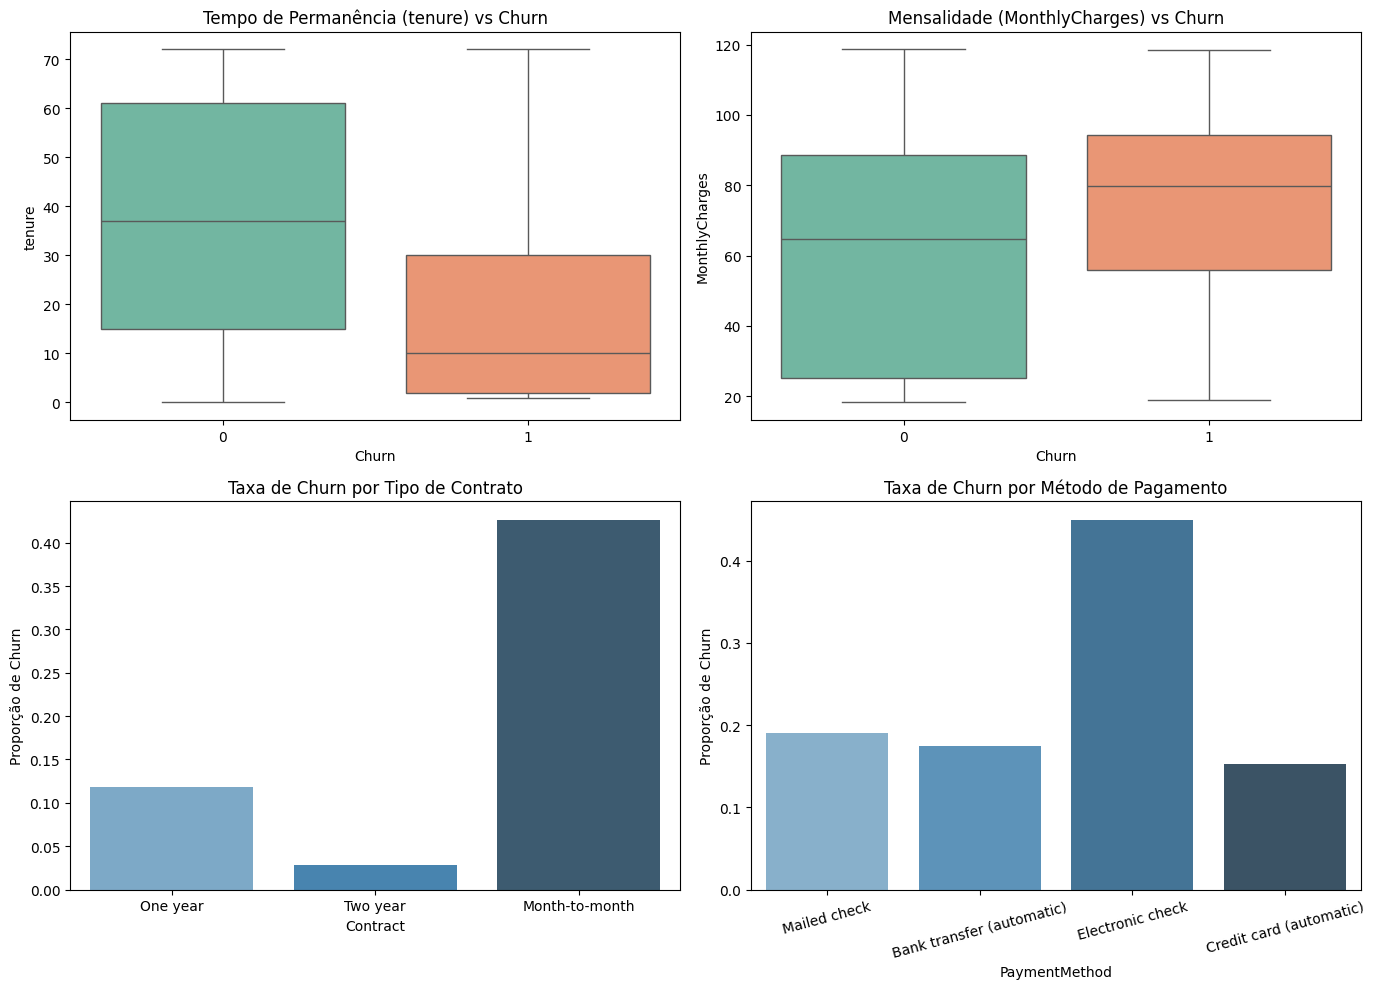

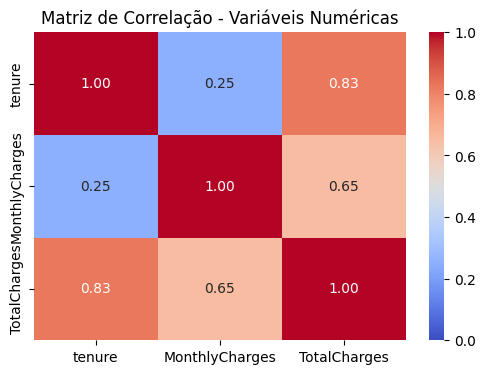

In [12]:
# Evitando vazamento de dados
tr = X_train.copy()
tr['Churn'] = y_train

# Proporção geral de cancelamento
print('Proporção de cancelamento')
print((tr['Churn'].value_counts(normalize = True)*100).round(2))

# Medidas descritivas para as variáveis númericas
num_cols = ['tenure','MonthlyCharges','TotalCharges']
print('Medidas descritivas para as variáveis númericas por Churn')
display(tr.groupby('Churn')[num_cols].describe().round(2).T)

# Grupos e Churn para variáveis categóricas
categ_cols = ['Contract', 'PaymentMethod', 'InternetService']

for categ in categ_cols:
  resumo = tr.groupby(categ)['Churn'].agg(
      Tamanho_Grupo = 'size',
      Taxa_cancelamento_Perc ='mean'
  ).round(4)

  resumo['Taxa_cancelamento_Perc'] = resumo['Taxa_cancelamento_Perc']*100
  print(f'Proporção de cancelamento por {categ}')
  display(resumo.sort_values(by='Taxa_cancelamento_Perc', ascending = False))

# Plotagem
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Númericas vs Churn
sns.boxplot(data=tr, x='Churn', y='tenure', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Tempo de Permanência (tenure) vs Churn')

sns.boxplot(data=tr, x='Churn', y='MonthlyCharges', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Mensalidade (MonthlyCharges) vs Churn')

# Categóricas vs Churn
sns.barplot(data=tr, x='Contract', y='Churn', errorbar=None, ax=axes[1, 0], palette='Blues_d')
axes[1, 0].set_title('Taxa de Churn por Tipo de Contrato')
axes[1, 0].set_ylabel('Proporção de Churn')

sns.barplot(data=tr, x='PaymentMethod', y='Churn', errorbar=None, ax=axes[1, 1], palette='Blues_d')
axes[1, 1].set_title('Taxa de Churn por Método de Pagamento')
axes[1, 1].set_ylabel('Proporção de Churn')
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(tr[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=0, vmax=1)
plt.title('Matriz de Correlação - Variáveis Numéricas')
plt.show()

Através do hetmap observamos que tenure e total charges possuem grande colineariedade

# Parte 3 - Seleção e Transformação das Variáveis

In [14]:
# Seleção e Transformação de variáveis

def engenharia_atributos(d):
  d = d.copy()

  servicos = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

  # Eliminando redundâncias
  for c in servicos:
    d[c] = d[c].replace({'No internet service': 'No'})
  d['MultipleLines'] = d['MultipleLines'].replace({'No phone service': 'No'})

  # Quantidade de serviços usados pelos clientes
  d['num_servicos_extras'] = (d[servicos] == 'Yes').sum(axis=1)

  # Houve aumento da mensalidade do cliente?
  d['ticket_medio'] = d['TotalCharges'] / d['tenure'].clip(lower=1)
  d['dif_preco'] = d['MonthlyCharges'] - d['ticket_medio']

  return d

X_train_eng = engenharia_atributos(X_train)
X_test_eng = engenharia_atributos(X_test)

# Removemos TotalCharges por sua redundância com tenure
num_cols = ['tenure', 'MonthlyCharges', 'num_servicos_extras', 'dif_preco']
cat_cols = X_train_eng.select_dtypes(include=['object']).columns.tolist()

# Aplicamos o StandarScaler para variáveis numéricas
# Aplicamos o OneHotEnconder para as categóricas, mas filtramos as que já são binárias para evitar duplicatas
preprocessor_eng = ColumnTransformer(transformers=[
    ('num',StandardScaler(),num_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), cat_cols)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelo_teste = LogisticRegression(max_iter=1000, random_state=42)

# Analisando com os dados originais(incluindo total charges)
num_base = ['tenure', 'MonthlyCharges', 'TotalCharges']
preprocessor_base = ColumnTransformer([
    ('num', StandardScaler(), num_base),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), cat_cols)
])
pipe_base = Pipeline([('prep',preprocessor_base), ('clf',modelo_teste)])
score_base = cross_val_score(pipe_base, X_train, y_train, cv=cv, scoring='average_precision').mean()

# Analisando com os dados transformados
pipe_eng = Pipeline([('prep',preprocessor_eng), ('clf',modelo_teste)])
score_eng = cross_val_score(pipe_eng, X_train_eng, y_train, cv=cv, scoring='average_precision').mean()

print(f"Desempenho (Average Precision) - Base Original: {score_base:.4f}")
print(f"Desempenho (Average Precision) - Base Transformada: {score_eng:.4f}")

Desempenho (Average Precision) - Base Original: 0.6479
Desempenho (Average Precision) - Base Transformada: 0.6454


A validação cruzada mostrou que criar variáveis não melhorou a precisão geral. A base transformada adicionou ruído aos dados.  Continuaremos analisando com o conjunto de dados mais simples.

# Parte 4 - Construção dos modelos

In [15]:
# Métricas a serem calculdas na validação cruzada
SCORING = {
    'ap': 'average_precision',
    'roc_auc': 'roc_auc',
    'f1': 'f1',
    'precisao': 'precision',
    'sensibilidade': 'recall'
}

# Definindo dicionários e hiperparâmetros
modelos_grid = {
    "Regressão Logística": (
        LogisticRegression(max_iter=1000,random_state=42),
      {"clf__C": [0.01, 0.1, 1, 10]}
    ),
    "Árvore de Decisão": (
        DecisionTreeClassifier(random_state=42),
        {"clf__max_depth": [3, 5, 7, 10], "clf__min_samples_split": [2, 10, 20]}
    ),

    "KNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [15, 31, 51], "clf__weights": ["uniform", "distance"]}
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {"clf__max_depth": [5, 10], "clf__n_estimators": [100, 200]}
    )
}

# Laço de treinamento
resultados_lista = []
resultados_cv = {}

for nome, (modelo, grid) in modelos_grid.items():
  # Cria o pipeline com o processor obtido no bloco 3
  pipe = Pipeline([('prep',preprocessor_base), ('clf',modelo)])

  # Decide pelo Average Precision
  grid_search = GridSearchCV(pipe, grid, cv=cv, scoring=SCORING, refit='ap', n_jobs=-1)

  # Treinando o modelo
  grid_search.fit(X_train, y_train)

  # Armazena os resultados
  resultados_cv[nome] = grid_search

  # Obtendo as melhores métricas
  id_melhor = grid_search.best_index_
  linha = {"Modelo": nome}

  for m in SCORING:
        linha[m] = float(grid_search.cv_results_[f"mean_test_{m}"][id_melhor])

  linha['Melhores Parâmetros'] = str(grid_search.best_params_)
  resultados_lista.append(linha)

# Exibição em tabela
df_resultados = pd.DataFrame(resultados_lista)

# Ordenando pelas métricas para deixar o Average Precision (ap) em destaque
colunas_ordem = ['Modelo', 'ap', 'roc_auc', 'f1', 'precisao', 'sensibilidade', 'Melhores Parâmetros']
df_resultados = df_resultados[colunas_ordem].sort_values(by='ap', ascending=False).reset_index(drop=True)

display(df_resultados.round(4))

,Modelo,ap,roc_auc,f1,precisao,sensibilidade,Melhores Parâmetros
0,Random Forest,0.6489,0.8352,0.5629,0.6497,0.4967,"{'clf__max_depth': 10, 'clf__n_estimators': 200}"
1,Regressão Logística,0.6479,0.8405,0.5862,0.6504,0.5341,{'clf__C': 1}
2,KNN,0.6178,0.8292,0.5931,0.6136,0.5742,"{'clf__n_neighbors': 51, 'clf__weights': 'unif..."
3,Árvore de Decisão,0.6058,0.8255,0.5955,0.6040,0.5876,"{'clf__max_depth': 5, 'clf__min_samples_split'..."


# Parte 5: Comparação dos métodos

In [16]:
# Coluna estratégia adicionada aos resultados do bloco 4
df_resultados['Estratégia'] = 'Original'

modelos_ponderados = {
    "Regressão Logística": (
        LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
        {"clf__C": [0.01, 0.1, 1, 10]}
    ),
    "Árvore de Decisão": (
        DecisionTreeClassifier(class_weight='balanced', random_state=42),
        {"clf__max_depth": [3, 5, 7, 10], "clf__min_samples_split": [2, 10, 20]}
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight='balanced', random_state=42),
        {"clf__max_depth": [5, 10], "clf__n_estimators": [100, 200]}
    )
}

# For para os modelos ponderados
resultados_ponderados = []

for nome, (modelo, grid) in modelos_ponderados.items():
    pipe = Pipeline([('prep', preprocessor_base), ('clf', modelo)])

    grid_search = GridSearchCV(pipe, grid, scoring=SCORING, refit='ap', cv=cv, n_jobs=-1)
    grid_search.fit(X_train, y_train)

    idx = grid_search.best_index_
    linha = {'Modelo': nome, 'Estratégia': 'Ponderado (class_weight)'}

    for m in SCORING:
        linha[m] = float(grid_search.cv_results_[f"mean_test_{m}"][idx])

    linha['Melhores Parâmetros'] = str(grid_search.best_params_)
    resultados_ponderados.append(linha)

# Unindo os resultados obtidos
df_ponderados = pd.DataFrame(resultados_ponderados)
df_final = pd.concat([df_resultados, df_ponderados], ignore_index=True)
df_final = df_final[['Modelo', 'Estratégia', 'ap', 'roc_auc', 'f1', 'precisao', 'sensibilidade', 'Melhores Parâmetros']]
tabela_cv = df_final.set_index(['Modelo', 'Estratégia']).sort_index()

print("Comparação de Métodos: Original vs Ponderado")
display(tabela_cv.round(4))

Comparação de Métodos: Original vs Ponderado


ap  roc_auc      f1  \
Modelo              Estratégia                                          
KNN                 Original                  0.6178   0.8292  0.5931   
Random Forest       Original                  0.6489   0.8352  0.5629   
                    Ponderado (class_weight)  0.6483   0.8365  0.6254   
Regressão Logística Original                  0.6479   0.8405  0.5862   
                    Ponderado (class_weight)  0.6464   0.8398  0.6207   
Árvore de Decisão   Original                  0.6058   0.8255  0.5955   
                    Ponderado (class_weight)  0.6017   0.8272  0.6083   

                                              precisao  sensibilidade  \
Modelo              Estratégia                                          
KNN                 Original                    0.6136         0.5742   
Random Forest       Original                    0.6497         0.4967   
                    Ponderado (class_weight)    0.5649         0.7005   
Regressão Logística Original                    0.6504         0.5341   
                    Ponderado (class_weight)    0.5100         0.7928   
Árvore de Decisão   Original                    0.6040         0.5876   
                    Ponderado (class_weight)    0.4970         0.7854   

                                                                            Melhores Parâmetros  
Modelo              Estratégia                                                                   
KNN                 Original                  {'clf__n_neighbors': 51, 'clf__weights': 'unif...  
Random Forest       Original                   {'clf__max_depth': 10, 'clf__n_estimators': 200}  
                    Ponderado (class_weight)   {'clf__max_depth': 10, 'clf__n_estimators': 200}  
Regressão Logística Original                                                      {'clf__C': 1}  
                    Ponderado (class_weight)                                    {'clf__C': 0.1}  
Árvore de Decisão   Original                  {'clf__max_depth': 5, 'clf__min_samples_split'...  
                    Ponderado (class_weight)  {'clf__max_depth': 5, 'clf__min_samples_split'...

# Parte 6 - Avaliação dos resultados

Teste de Classificação
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.69      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.82      0.82      0.82      1409

ROC-AUC: 0.8622
Average Precision (AP): 0.6815

10% de risco-
Cancelamentos reais em 10% da base: 28.2%
Lift: Contatar este grupo é 2.8 vezes mais efetivo do que ligar aleatoriamente.

Efeito do limiar de decisão
Limiar padrão: 0.500 | Limiar ótimo (F1) calculado no Treino: 0.297

Matriz de Confusão com Limiar Padrão (0.50):
[[934 102]
 [149 224]]

Matriz de Confusão com Limiar Ótimo (0.297):
[[793 243]
 [ 73 300]]


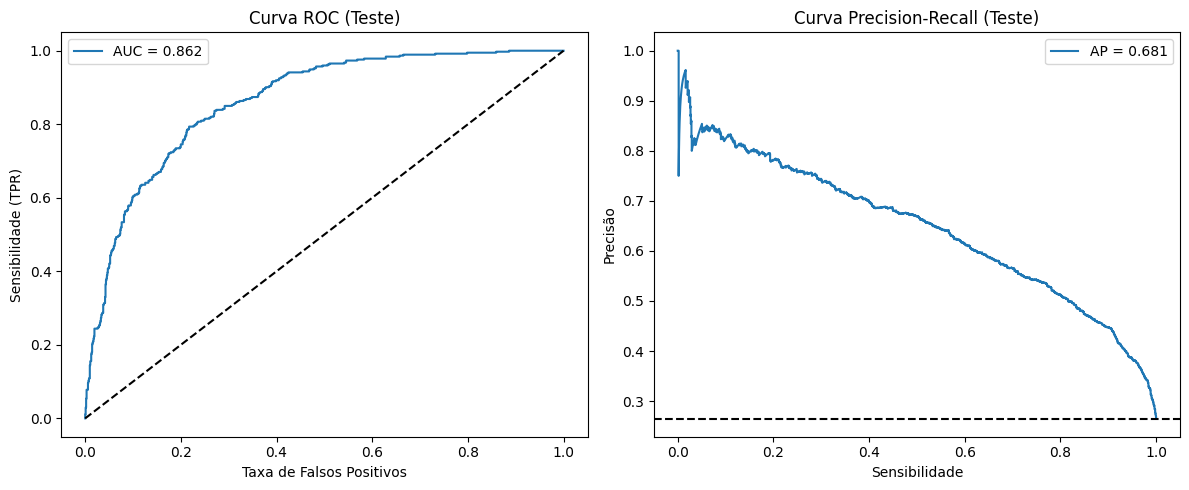

In [17]:
# O melhor modelo do bloco 4 foi o Regressão Linear
melhor_grid_search = resultados_cv['Regressão Logística']
melhor_modelo = melhor_grid_search.best_estimator_

# Avaliando no modelo de teste
y_pred = melhor_modelo.predict(X_test)
y_proba = melhor_modelo.predict_proba(X_test)[:, 1]

print("Teste de Classificação")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")
print(f"Average Precision (AP): {average_precision_score(y_test, y_proba):.4f}")

# Se a empresa contatar apenas 10% dos clientes, qual proporção dos cancelamentos
# seria identificada?
frac = 0.10
k = int(np.ceil(frac * len(y_test)))
idx = np.argsort(-y_proba)[:k]
canc_capturados = y_test.iloc[idx].sum()
canc_totais = y_test.sum()
recall_top10 = canc_capturados / canc_totais
lift = (canc_capturados / k) / y_test.mean()

print("\n10% de risco-")
print(f"Cancelamentos reais em 10% da base: {recall_top10 * 100:.1f}%")
print(f"Lift: Contatar este grupo é {lift:.1f} vezes mais efetivo do que ligar aleatoriamente.")

# Cálculo do Limiar Ótimo de Decisão
oof_proba = cross_val_predict(melhor_modelo, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
p, r, t = precision_recall_curve(y_train, oof_proba)
f1_scores = 2 * p * r / (p + r + 1e-12)
limiar_otimo = t[np.nanargmax(f1_scores[:-1])]

print(f"\nEfeito do limiar de decisão")
print(f"Limiar padrão: 0.500 | Limiar ótimo (F1) calculado no Treino: {limiar_otimo:.3f}")

# Reavaliando o teste com o novo limiar
y_pred_otimo = (y_proba >= limiar_otimo).astype(int)
print("\nMatriz de Confusão com Limiar Padrão (0.50):")
print(confusion_matrix(y_test, y_pred))
print(f"\nMatriz de Confusão com Limiar Ótimo ({limiar_otimo:.3f}):")
print(confusion_matrix(y_test, y_pred_otimo))

# Gráficos
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[0].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, y_proba):.3f}')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title('Curva ROC (Teste)')
axes[0].set_xlabel('Taxa de Falsos Positivos')
axes[0].set_ylabel('Sensibilidade (TPR)')
axes[0].legend()

# Curva Precision-Recall
axes[1].plot(r, p, label=f'AP = {average_precision_score(y_test, y_proba):.3f}')
axes[1].axhline(y_test.mean(), color='k', ls='--')
axes[1].set_title('Curva Precision-Recall (Teste)')
axes[1].set_xlabel('Sensibilidade')
axes[1].set_ylabel('Precisão')
axes[1].legend()

plt.tight_layout()
plt.show()

# Parte 7 - Análise de estratégias de balanceamento

In [18]:
# Escolhemos o modelo que obteve pior sensibilidade
modelo_base = RandomForestClassifier(random_state=42)
grid_rf = {"clf__max_depth": [5, 10], "clf__n_estimators": [100, 200]}

amostradores = {
    "Undersampling (RUS)": RandomUnderSampler(random_state=42),
    "Oversampling (ROS)": RandomOverSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42)
}

resultados_reamostragem = []

for nome_estrategia, sampler in amostradores.items():

    pipe_imb = ImbPipeline([
        ('prep', preprocessor_base), # Nosso pré-processador do Bloco 3
        ('sampler', sampler),        # Técnica de reamostragem
        ('clf', modelo_base)         # O classificador
    ])

    # Otimização com o GridSearchCV
    gs = GridSearchCV(pipe_imb, grid_rf, scoring=SCORING, refit='ap', cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)

    idx = gs.best_index_
    linha = {'Estratégia': nome_estrategia}

    # Extrai as métricas
    for m in SCORING:
        linha[m] = float(gs.cv_results_[f"mean_test_{m}"][idx])

    linha['Melhores Parâmetros'] = str(gs.best_params_)
    resultados_reamostragem.append(linha)

    # Construindo a tabela final
df_reamostragem = pd.DataFrame(resultados_reamostragem)

# Recuperando o desempenho da Random Forest
rf_historico = df_final[df_final['Modelo'] == 'Random Forest'].copy()
rf_historico = rf_historico.drop(columns=['Modelo'])

# Unindo numa única tabela
comparativo_rf = pd.concat([rf_historico, df_reamostragem], ignore_index=True)
comparativo_rf = comparativo_rf[['Estratégia', 'ap', 'roc_auc', 'f1', 'precisao', 'sensibilidade', 'Melhores Parâmetros']]
comparativo_rf = comparativo_rf.sort_values(by='ap', ascending=False).set_index('Estratégia')

print("Balanceamento para o Random Forest")
display(comparativo_rf.round(4))

Balanceamento para o Random Forest


,ap,roc_auc,f1,precisao,sensibilidade,Melhores Parâmetros
Estratégia,,,,,,
Original,0.6489,0.8352,0.5629,0.6497,0.4967,"{'clf__max_depth': 10, 'clf__n_estimators': 200}"
Ponderado (class_weight),0.6483,0.8365,0.6254,0.5649,0.7005,"{'clf__max_depth': 10, 'clf__n_estimators': 200}"
Oversampling (ROS),0.6474,0.8346,0.6245,0.5429,0.7353,"{'clf__max_depth': 10, 'clf__n_estimators': 200}"
Undersampling (RUS),0.6438,0.8385,0.6175,0.5019,0.8028,"{'clf__max_depth': 5, 'clf__n_estimators': 200}"
SMOTE,0.6407,0.8345,0.6226,0.5685,0.6885,"{'clf__max_depth': 10, 'clf__n_estimators': 200}"


# Parte 8 - Interpretação e discussão crítica

Calculando Permutation Importance


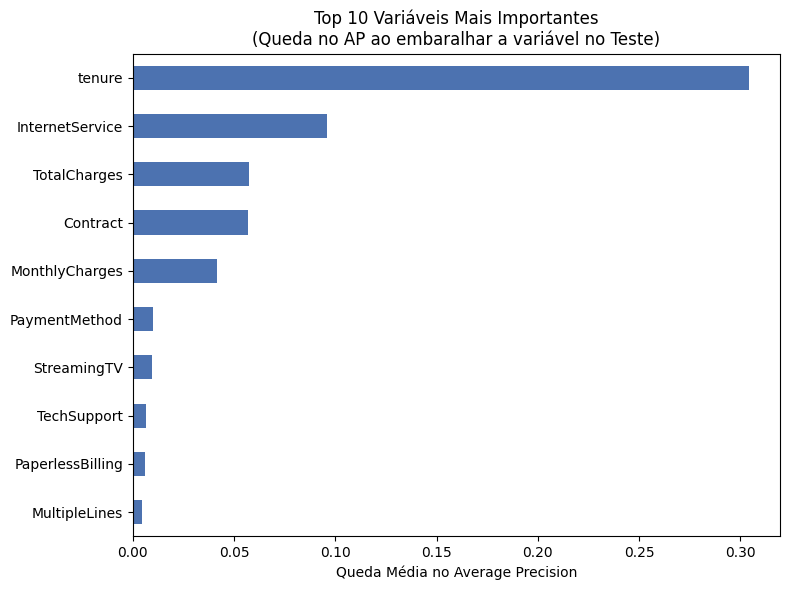


--- FATORES DE PROTEÇÃO (Reduzem o risco de cancelamento) ---
num__tenure                                0.256
cat__Contract_Two year                     0.420
cat__InternetService_DSL                   0.549
num__MonthlyCharges                        0.660
cat__OnlineSecurity_No internet service    0.747
dtype: float64

--- FATORES DE RISCO (Aumentam o risco de cancelamento) ---
cat__PaymentMethod_Electronic check    1.179
cat__PaperlessBilling_Yes              1.396
cat__InternetService_Fiber optic       1.602
cat__Contract_Month-to-month           1.731
num__TotalCharges                      1.937
dtype: float64

--- TABELA DE DECIS (Priorização de Ações de Marketing) ---


,Volume_Clientes,Cancelamentos_Capturados,Taxa_Acerto_No_Grupo,Recall_Acumulado (%)
Decil,,,,
1,141,105,0.745,28.2
2,141,94,0.667,53.4
3,141,56,0.397,68.4
4,141,49,0.348,81.5
5,140,25,0.179,88.2
6,141,25,0.177,94.9
7,141,11,0.078,97.9
8,141,4,0.028,98.9
9,141,3,0.021,99.7


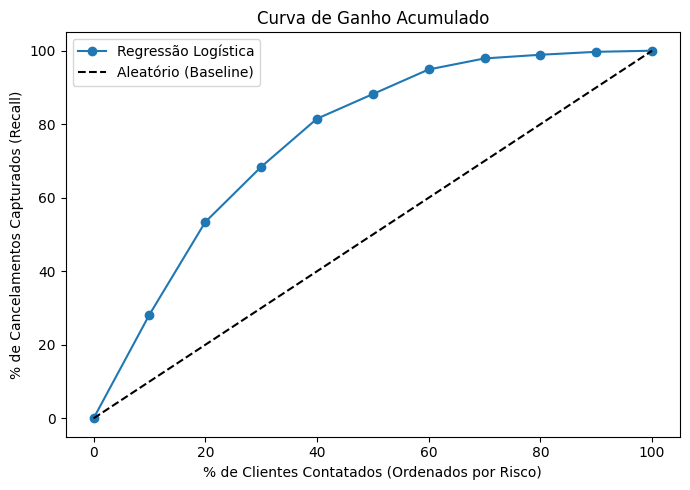

In [19]:
modelo_lr = resultados_cv['Regressão Logística'].best_estimator_

# 1) - Qual variável derruba o modelo se faltar?
print("Calculando Permutation Importance")
resultado_imp = permutation_importance(modelo_lr, X_test, y_test,
                                       scoring='average_precision',
                                       n_repeats=10, random_state=42, n_jobs=-1)

# Agrupa pela variável original (antes do OneHotEncoder)
importancias = pd.Series(resultado_imp.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 6))
importancias.tail(10).plot(kind='barh', color='#4C72B0')
plt.title('Top 10 Variáveis Mais Importantes\n(Queda no AP ao embaralhar a variável no Teste)')
plt.xlabel('Queda Média no Average Precision')
plt.tight_layout()
plt.show()


# 2) Como categoria afeta o churn
# Extraímos o nome das colunas geradas após o pré-processamento e os coeficientes do modelo
nomes_features = modelo_lr.named_steps['prep'].get_feature_names_out()
coeficientes = modelo_lr.named_steps['clf'].coef_[0]

# np.exp() converte log-odds da Regressão Logística para Odds Ratios (Razões de Chances)
razoes = pd.Series(np.exp(coeficientes), index=nomes_features).sort_values()

print("\nReduzem o risco de cancelamento")
# Valores menores que 1 indicam redução de risco
print(razoes.head(5).round(3))

print("\nAumentam o risco de cancelamento")
# Valores maiores que 1 indicam aumento de risco
print(razoes.tail(5).round(3))

# 3) Análise de Negócio e ROI
proba_teste = modelo_lr.predict_proba(X_test)[:, 1]
tab = pd.DataFrame({'Churn_Real': y_test.values, 'Probabilidade': proba_teste})

# Ordena e divide os clientes em 10 grupos iguais (Decil 1 = Maior Risco de Cancelamento)
tab['Decil'] = 10 - pd.qcut(tab['Probabilidade'].rank(method='first'), 10, labels=False)

ganho = tab.groupby('Decil')['Churn_Real'].agg(
    Volume_Clientes='size',
    Cancelamentos_Capturados='sum'
)

# Calcula as métricas acumuladas e de eficiência
ganho['Taxa_Acerto_No_Grupo'] = (ganho['Cancelamentos_Capturados'] / ganho['Volume_Clientes']).round(3)
ganho['Recall_Acumulado (%)'] = (ganho['Cancelamentos_Capturados'].cumsum() / ganho['Cancelamentos_Capturados'].sum() * 100).round(1)

print("\nPriorização de Ações de Marketing")
display(ganho)

# Gráfico de Ganho Acumulado
plt.figure(figsize=(7, 5))
plt.plot(np.insert(ganho.index.values * 10, 0, 0),
         np.insert(ganho['Recall_Acumulado (%)'].values, 0, 0),
         marker='o', label='Regressão Logística')
plt.plot([0, 100], [0, 100], 'k--', label='Aleatório (Baseline)')
plt.title('Curva de Ganho Acumulado')
plt.xlabel('% de Clientes Contatados (Ordenados por Risco)')
plt.ylabel('% de Cancelamentos Capturados (Recall)')
plt.legend()
plt.tight_layout()
plt.show()